In [1]:
print("In the name of Allah")

In the name of Allah


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score


from sklearn.cluster import KMeans

# Problem 1: Mall Customer Segmentation


In [3]:
df = pd.read_csv('Mall_Customers.csv')

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Feature scaling is important before applying K-Means because the algorithm uses distance (usually Euclidean distance) to group data points. If features have different scales, the feature with the larger values will dominate the distance calculation.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [5]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

X.head(5)

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

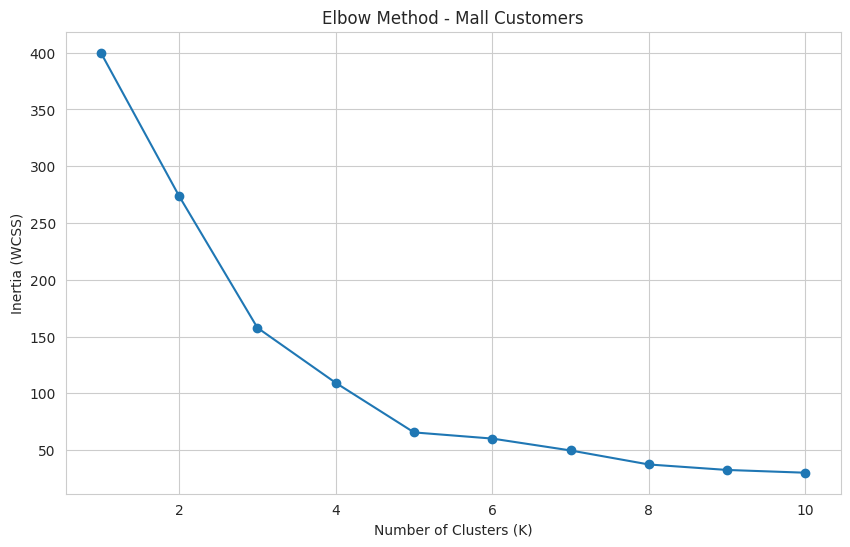

K=1: inertia=400.00
K=2: inertia=273.67
K=3: inertia=157.70
K=4: inertia=109.23
K=5: inertia=65.57
K=6: inertia=60.13
K=7: inertia=49.67
K=8: inertia=37.32
K=9: inertia=32.50
K=10: inertia=30.06


In [7]:
inertias = []

for k in range(1, 11) :
  km = KMeans(
      n_clusters = k,
      init = 'k-means++',
      random_state = 42
  )

  km.fit(X_scaled)
  inertias.append(km.inertia_)

plt.figure(figsize = (10, 6))
plt.plot(range(1, 11), inertias, marker = 'o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method - Mall Customers")

plt.show()

for k, i in zip(range(1,11), inertias):
    print(f"K={k}: inertia={i:.2f}")

In [8]:
kmeans = KMeans(
    n_clusters = 5,
    init = "k-means++",
    random_state = 42
)

kmeans.fit(X_scaled)

KMeans(n_clusters=5, random_state=42)

In [9]:
df['clusters'] = kmeans.labels_

In [10]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),clusters
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


In [11]:
df['clusters'].unique()

array([4, 2, 0, 1, 3], dtype=int32)

In [12]:
print("Customers per cluster:")
print(df['clusters'].value_counts().sort_index())

Customers per cluster:
clusters
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [13]:
centers = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns = ['Annual Income (k$)', 'Spending Score (1-100)']
)

print("Cluster Centers:")
print(kmeans.cluster_centers_)

Cluster Centers:
[[-0.20091257 -0.02645617]
 [ 0.99158305  1.23950275]
 [-1.32954532  1.13217788]
 [ 1.05500302 -1.28443907]
 [-1.30751869 -1.13696536]]


In [14]:
centers.index.name = 'Cluster'
print("\nCluster centers (original units):")
print(centers.round(1))


Cluster centers (original units):
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                      55.3                    49.5
1                      86.5                    82.1
2                      25.7                    79.4
3                      88.2                    17.1
4                      26.3                    20.9


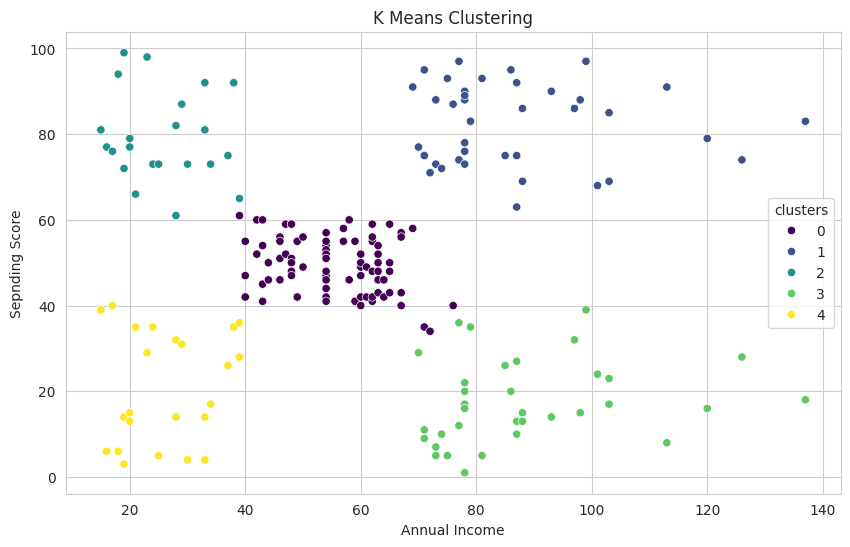

In [15]:
plt.figure(figsize = (10, 6))

sns.scatterplot(
    data = df,
    x = "Annual Income (k$)",
    y = "Spending Score (1-100)",
    hue = 'clusters',
    palette='viridis'
)

plt.title("K Means Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Sepnding Score")

plt.show()

The cluster with both high income and high spending score (Cluster 1 above).
These customers have both the *financial capacity* (high income) and the *willingness to spend* (high spending
score) — the two conditions required to buy luxury goods. The high-income/low-spending cluster (Cluster 3) has
the money but historically doesn't spend it, so they are a weaker target without a different marketing approach
(e.g., exclusivity/status appeals rather than discounts).

# Problem 2: Iris Dataset Clustering


In [16]:
df = pd.read_csv('Iris.csv')

df.head(5)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [17]:
X = df[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [18]:
print(X_scaled[:5])

[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


The four features — sepal length, sepal width, petal length, petal width (all in cm) — happen to already be on a
similar scale here, but petal length/width vary more (larger range/variance) than sepal width. K-Means still uses
Euclidean distance across all 4 dimensions, so **any** feature with larger variance will dominate cluster
assignment unless we standardize. Scaling (`StandardScaler`) ensures each of the 4 measurements contributes
proportionally to its actual biological signal, not to its raw units/variance — important since we're combining
length and width measurements from two different plant parts.

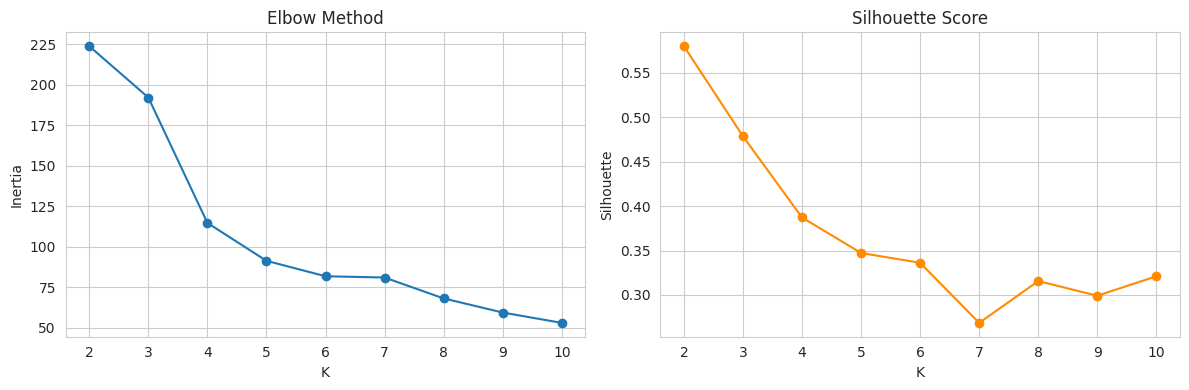

In [19]:
inertias, silsi = [], []

for k in range(2, 11) :
  km = KMeans(n_clusters = k,
              init = "k-means++",
              random_state = 42
            )

  labels = km.fit_predict(X_scaled)
  inertias.append(km.inertia_)
  silsi.append( silhouette_score( X_scaled, labels ) )


fig, axes = plt.subplots(1, 2, figsize = (12, 4))

axes[0].plot( range(2, 11), inertias, marker = 'o' )
axes[0].set_title("Elbow Method")
axes[0].set_xlabel( "K" )
axes[0].set_ylabel( "Inertia" )

axes[1].plot( range(2, 11), silsi, marker = 'o', color = 'darkorange' )
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()


In [20]:
for k, i, s in zip(range(2, 11), inertias, silsi):
    print(f"K={k}: inertia={i:.2f}, silhouette={s:.3f}")

K=2: inertia=223.73, silhouette=0.580
K=3: inertia=192.04, silhouette=0.479
K=4: inertia=114.68, silhouette=0.387
K=5: inertia=91.30, silhouette=0.347
K=6: inertia=81.76, silhouette=0.336
K=7: inertia=80.98, silhouette=0.269
K=8: inertia=68.09, silhouette=0.316
K=9: inertia=59.39, silhouette=0.299
K=10: inertia=52.99, silhouette=0.321


In [21]:
kmeans = KMeans(
    n_clusters = 3,
    init = "k-means++",
    n_init = 10,
    random_state = 42
)

kmeans.fit(X_scaled)

KMeans(n_clusters=3, n_init=10, random_state=42)

In [22]:
df['clusters'] = kmeans.labels_

df.head(5)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,clusters
0,1,5.1,3.5,1.4,0.2,Iris-setosa,1
1,2,4.9,3.0,1.4,0.2,Iris-setosa,1
2,3,4.7,3.2,1.3,0.2,Iris-setosa,1
3,4,4.6,3.1,1.5,0.2,Iris-setosa,1
4,5,5.0,3.6,1.4,0.2,Iris-setosa,1


In [23]:
df['clusters'].unique()

array([1, 2, 0], dtype=int32)

In [24]:
print(df['clusters'].value_counts().sort_index())

clusters
0    53
1    50
2    47
Name: count, dtype: int64


In [25]:
df['Species'].unique()

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [26]:
compare = pd.crosstab(df['clusters'], df['Species'])

print(compare)


Species   Iris-setosa  Iris-versicolor  Iris-virginica
clusters                                              
0                   0               39              14
1                  50                0               0
2                   0               11              36


# Problem 3: Credit Card Customer Segmentation


In [27]:
df = pd.read_csv("CC GENERAL.csv")

df.head(5)

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [28]:
df.isnull().sum()

,0
CUST_ID,0
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,0
PURCHASES_INSTALLMENTS_FREQUENCY,0


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [30]:
df[["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]].describe()

,CREDIT_LIMIT,MINIMUM_PAYMENTS
count,8949.000000,8637.000000
mean,4494.449450,864.206542
std,3638.815725,2372.446607
min,50.000000,0.019163
25%,1600.000000,169.123707
50%,3000.000000,312.343947
75%,6500.000000,825.485459
max,30000.000000,76406.207520


<Axes: xlabel='CREDIT_LIMIT', ylabel='Density'>

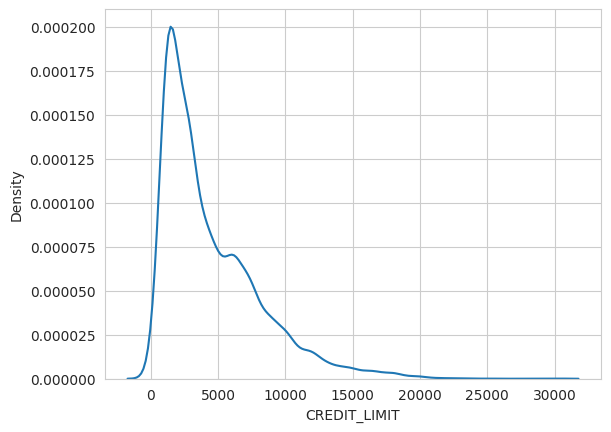

In [31]:
sns.kdeplot(data = df, x = "CREDIT_LIMIT")

<Axes: xlabel='MINIMUM_PAYMENTS', ylabel='Density'>

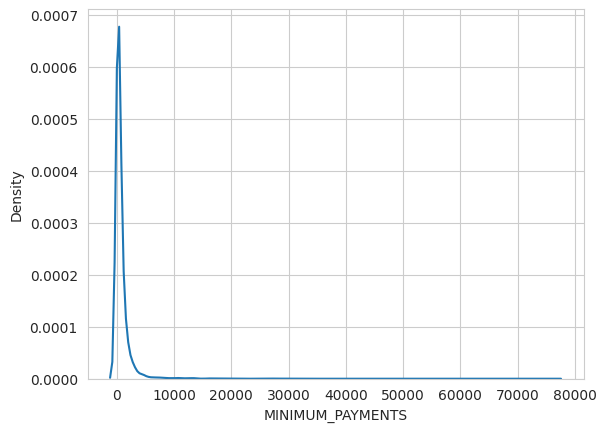

In [32]:
sns.kdeplot(data = df,
            x = "MINIMUM_PAYMENTS"
            )


In [33]:
imputer = SimpleImputer(strategy = 'median')
df[["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]] = imputer.fit_transform( df[["CREDIT_LIMIT", "MINIMUM_PAYMENTS"]] )

In [34]:
df.isnull().sum()

,0
CUST_ID,0
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,0
PURCHASES_INSTALLMENTS_FREQUENCY,0


In [35]:
X = df.drop('CUST_ID', axis = 1)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

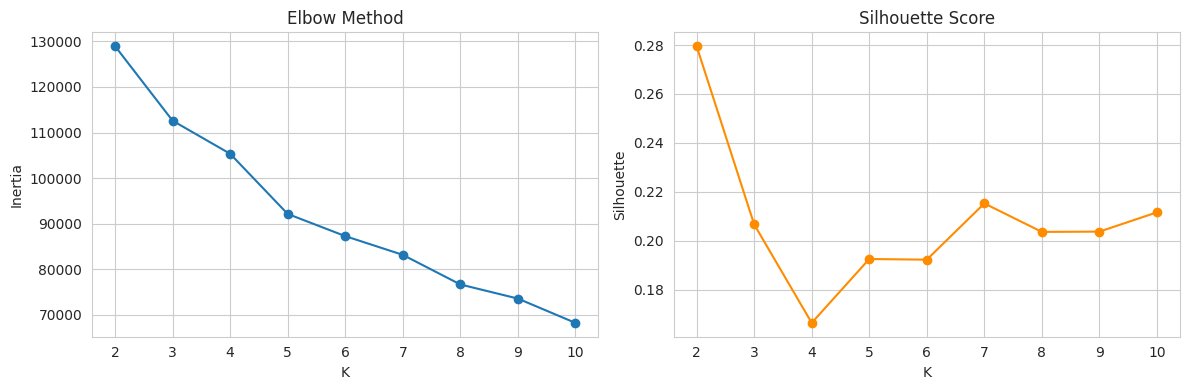

In [36]:
inertias, silsi = [], []

for k in range( 2, 11 ) :
  km = KMeans(
      n_clusters = k,
      init = "k-means++",
      random_state = 42
  )

  labels = km.fit_predict(X_scaled)
  inertias.append(km.inertia_)
  silsi.append( silhouette_score(X_scaled,
                                 labels,
                                 random_state = 42) )

fig, axes = plt.subplots(1, 2, figsize = (12, 4))

axes[0].plot( range(2, 11), inertias, marker = 'o' )
axes[0].set_title("Elbow Method")
axes[0].set_xlabel( "K" )
axes[0].set_ylabel( "Inertia" )

axes[1].plot( range(2, 11), silsi, marker = 'o', color = 'darkorange' )
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()


In [37]:
for k, i, s in zip(range(2, 11), inertias, silsi):
    print(f"K={k}: inertia={i:.1f}, silhouette={s:.3f}")

K=2: inertia=128953.4, silhouette=0.280
K=3: inertia=112596.4, silhouette=0.207
K=4: inertia=105339.7, silhouette=0.166
K=5: inertia=92131.5, silhouette=0.193
K=6: inertia=87266.6, silhouette=0.192
K=7: inertia=83154.0, silhouette=0.215
K=8: inertia=76655.4, silhouette=0.204
K=9: inertia=73554.5, silhouette=0.204
K=10: inertia=68221.1, silhouette=0.212


In [38]:
kmeans = KMeans(
    n_clusters  = 4,
    init = "k-means++",
    max_iter = 400,
    random_state = 42
)

kmeans.fit(X_scaled)

KMeans(max_iter=400, n_clusters=4, random_state=42)

In [39]:
df['clusters'] = kmeans.labels_

In [40]:
df['clusters'].unique()

array([3, 0, 2, 1], dtype=int32)

In [41]:
print("Customers per clusters :")
print( df['clusters'].value_counts().sort_index() )

Customers per clusters :
clusters
0     977
1    1487
2    3118
3    3368
Name: count, dtype: int64


In [42]:
print("\nAverage BALANCE / PURCHASES / CREDIT_LIMIT / PAYMENTS by cluster :\n")

summary = df.groupby('clusters')[['BALANCE','PURCHASES','CREDIT_LIMIT','PAYMENTS']].mean().round(1)

print(summary)


Average BALANCE / PURCHASES / CREDIT_LIMIT / PAYMENTS by cluster :

          BALANCE  PURCHASES  CREDIT_LIMIT  PAYMENTS
clusters                                            
0          5010.4      716.0        8208.7    4173.8
1           108.4      350.2        3632.1    1036.9
2          1253.8     2182.0        5122.0    2148.6
3          1495.3      283.5        3216.3     948.0


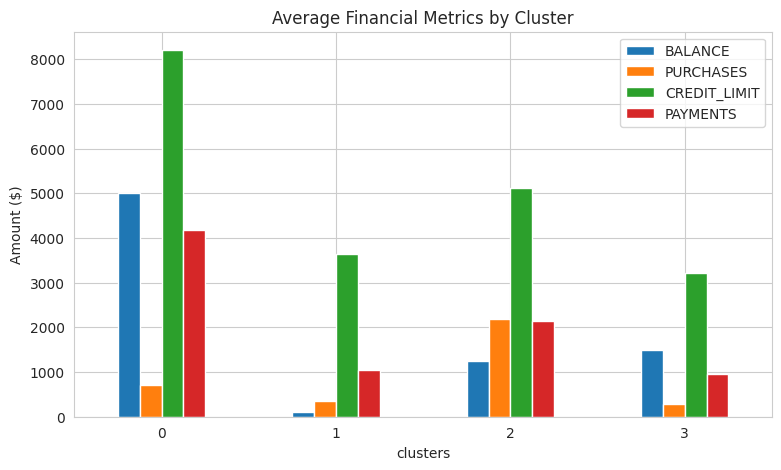

In [43]:
summary.plot(kind='bar', figsize=(9,5))

plt.title('Average Financial Metrics by Cluster')
plt.ylabel('Amount ($)')
plt.xticks(rotation=0)
plt.show()

In [44]:
risk_view = df.groupby('clusters')[['CASH_ADVANCE','CASH_ADVANCE_FREQUENCY','PRC_FULL_PAYMENT']].mean().round(3)
print(risk_view)

          CASH_ADVANCE  CASH_ADVANCE_FREQUENCY  PRC_FULL_PAYMENT
clusters                                                        
0             5065.975                   0.509             0.040
1              299.482                   0.035             0.254
2              234.565                   0.042             0.283
3              782.285                   0.158             0.023


Riskiest: Cluster 0 — huge cash advance use ($5,066) and highest frequency (0.509), but only 4% pay in full.
Most profitable: Cluster 2 — lowest cash advance reliance, highest full-payment rate (0.283) — disciplined, low-risk customers.

# Problem 4: Anomaly Detection with K-Means

Dataset Link : https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

In [62]:
df = pd.read_csv("creditcard.csv")

df.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [63]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [64]:
df = df.dropna()


In [66]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [67]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [68]:
df['Class'].describe()

,Class
count,284807.000000
mean,0.001727
std,0.041527
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


In [69]:
fraud_pct = 100 * df['Class'].mean()

print(f"Fraud percentage : {round(fraud_pct, 2)}%")

Fraud percentage : 0.17%


In [70]:
X = df.drop('Class', axis = 1)

X.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99


In [71]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [72]:
kmeans = KMeans(
    n_clusters = 10,
    init = "k-means++",
    random_state = 42
)

kmeans.fit(X_scaled)

KMeans(n_clusters=10, random_state=42)

In [73]:
df['clusters'] = kmeans.labels_

print(df['clusters'])

0         9
1         9
2         0
3         7
4         9
         ..
284802    4
284803    0
284804    1
284805    5
284806    5
Name: clusters, Length: 284807, dtype: int32


In [79]:
distances = kmeans.transform(X_scaled)
df['distance_to_center'] = np.min(distances, axis=1)
print(df[['clusters', 'distance_to_center']].sample(10))

        clusters  distance_to_center
23206          9            3.680616
266258         5            3.280470
19989          9            3.741628
192540         7            4.109162
1327           9            4.756231
224724         5            2.773604
97960          9            3.618525
182259         1            4.737479
208786         2            5.448385
108371         9            3.197962


In [75]:
df['clusters'].unique()

array([9, 0, 7, 2, 8, 4, 3, 6, 5, 1], dtype=int32)

In [87]:
threshold = np.percentile(df['distance_to_center'], 95)

df['pred_anomaly'] = (df['distance_to_center'] > threshold).astype(int)

print(f"95th percentile distance threshold: {threshold:.3f}")


95th percentile distance threshold: 6.787


In [88]:
detected = df[(df['Class'] == 1) & (df['pred_anomaly'] == 1)].shape[0]

total_frauds = df['Class'].sum()
print(f"Frauds detected: {detected} / {total_frauds}")

Frauds detected: 417 / 492


In [92]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

cm = confusion_matrix(df['Class'], df['pred_anomaly'])
print("Confusion Matrix:\n", cm)

prec = precision_score(df['Class'], df['pred_anomaly'])
rec = recall_score(df['Class'], df['pred_anomaly'])
print(f"\nPrecision: {prec:.4f}")
print(f"Recall: {rec:.4f}")

Confusion Matrix:
 [[270491  13824]
 [    75    417]]

Precision: 0.0293
Recall: 0.8476


The 2.93% Precision (The Alert Fatigue): This is exactly what Point 1 warns about. By using a blind "top 5%" distance threshold on highly imbalanced data, the model forced over 13,000 normal transactions into the fraud bucket. It causes massive false alarms.

The 75 Missed Frauds (False Negatives): This highlights Points 2 and 3. K-Means assumes simple, round clusters and relies strictly on distance. Because of this, 75 clever frauds managed to mimic normal behavior and blend right in near the cluster centers.

The 84.76% Recall (The Blind Catch): The model caught a good chunk of fraud, but as Point 5 notes, it did so completely blindly without looking at the actual labels It's a clumsy net that catches the bad guys but scoops up thousands of innocent people with them.